# 06 · Descriptive and diagnostic EDA
Transforms the cleaned tables, then describes what happened and diagnoses why. Run after Notebook 01.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False,'font.size':9,'axes.titleweight':'bold','axes.titlesize':10})
BLUE,ORANGE,AQUA,YELLOW,GREY='#2a78d6','#eb6834','#1baf7a','#eda100','#8a8984'
F='../Results/figures/eda/'; pretty=lambda s:str(s).replace('_',' ')
c=pd.read_csv('../Dataset/customers.csv'); ca=pd.read_csv('../Dataset/campaigns.csv'); t=pd.read_csv('../Dataset/transactions.csv'); raw=pd.read_csv('../Dataset/raw/GroupBuy_Mock_Survey_Data.csv')

## Transformation

In [2]:
c['High_Intent']=(c.Conversion_Segment=='High').astype(int)
c['Log_Spend']=np.log1p(c.B1_Monthly_Spend_Eligible_AED); c['Log_Income']=np.log1p(c.A7_Monthly_Income_AED)
c['Income_Band']=pd.cut(c.A7_Monthly_Income_AED,[0,10000,20000,35000,150000],labels=['<10k','10-20k','20-35k','35k+'])
c['Prior_Group_Buying']=c.B4_Used_Group_Buying_Before.map({'No':0,'Yes, once or twice':1,'Yes, regularly':2})
c['WhatsApp_Group']=(c.B5_In_Community_WhatsApp_Buying_Group=='Yes').astype(int)
c['Pilot_Register']=c.G2_Register_For_Pilot.map({'No':0,'Maybe':1,'Yes':2}); c['Shared_Contact']=(c.G3_Share_Contact_For_Pilot=='Yes').astype(int)
c['Category_Count']=c.filter(like='CAT_').sum(axis=1); c['Feature_Count']=c.filter(like='FEAT_').sum(axis=1)
ca['Month']=ca.Start_Date.str[:7]; ca['Target_Attainment']=ca.Pledged_Qty/ca.Target_Qty; ca['Paid_Share']=ca.Paid_Buyers/ca.Committed_Buyers
c.to_csv('../Dataset/customers_transformed.csv',index=False); ca.to_csv('../Dataset/campaigns_transformed.csv',index=False)
out={}
print(c[['A2_Age','A7_Monthly_Income_AED','B1_Monthly_Spend_Eligible_AED','B2_Online_Orders_Per_Month','F1_Min_Discount_To_Switch_Pct','F2_Max_Wait_Days','G4_Expected_Order_Value_AED','Conversion_Score_0to10']].describe().T[['count','mean','50%','std','min','max']].round(1).to_string())
print('skew spend/log',c.B1_Monthly_Spend_Eligible_AED.skew().round(2),c.Log_Spend.skew().round(2))

                                count     mean      50%      std     min       max
A2_Age                         1172.0     36.7     37.0      8.7    18.0      60.0
A7_Monthly_Income_AED          1081.0  24207.8  18700.0  16529.5  5400.0  108700.0
B1_Monthly_Spend_Eligible_AED  1197.0   4041.8   2510.0   7904.8     0.0  110358.0
B2_Online_Orders_Per_Month     1159.0      6.7      6.0      4.0     0.0      17.0
F1_Min_Discount_To_Switch_Pct  1194.0     16.7     16.0      7.0     2.0      38.0
F2_Max_Wait_Days               1164.0      5.4      5.0      3.1     0.0      15.0
G4_Expected_Order_Value_AED    1200.0    725.7    490.0    711.8    50.0    6320.0
Conversion_Score_0to10         1200.0      4.2      4.1      3.1     0.0      10.0
skew spend/log 10.09 -0.05


                         s     n
0       Survey respondents  1200
1  Registered Yes or Maybe   693
2           Registered Yes   328
3   Yes and shared contact   222
                             s     n
0                  Commitments  4449
1  In campaigns reaching offer  4029
2                  Paid orders  2218
3          Repeat-buyer orders  2046


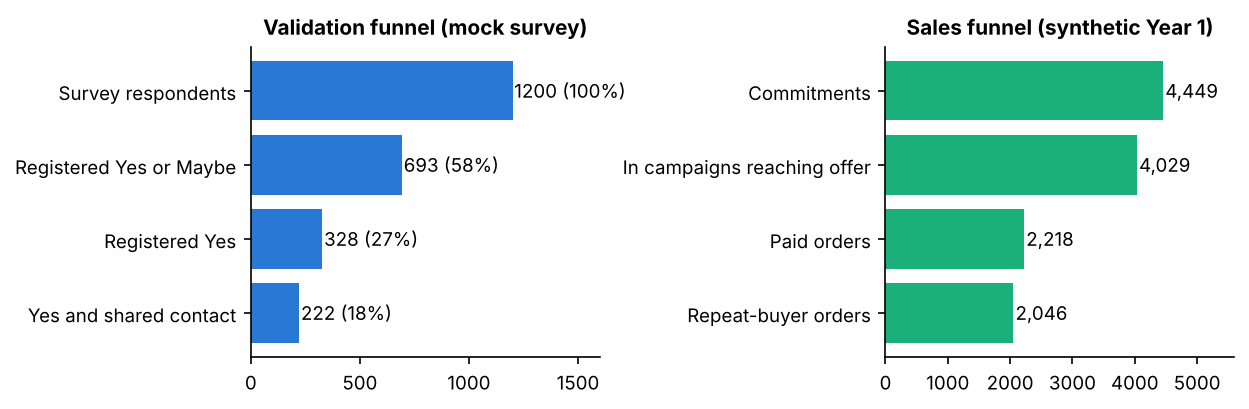

In [3]:
f=[('Survey respondents',len(c)),('Registered Yes or Maybe',(c.G2_Register_For_Pilot!='No').sum()),('Registered Yes',(c.G2_Register_For_Pilot=='Yes').sum()),('Yes and shared contact',((c.G2_Register_For_Pilot=='Yes')&(c.Shared_Contact==1)).sum())]
d=pd.DataFrame(f,columns=['s','n']); print(d.to_string())
fig,ax=plt.subplots(1,2,figsize=(8.4,2.8))
ax[0].barh(d.s[::-1],d.n[::-1],color=BLUE); ax[0].set_title('Validation funnel (mock survey)')
for i,v in enumerate(d.n[::-1]): ax[0].text(v+8,i,f'{v} ({v/len(c):.0%})',va='center')
ax[0].set_xlim(0,1600)
offer=ca[ca.Status.isin(['Completed','Cancelled - low conversion'])]
g=[('Commitments',len(t)),('In campaigns reaching offer',t.Campaign_ID.isin(offer.Campaign_ID).sum()),('Paid orders',int(t.Paid.sum())),('Repeat-buyer orders',int(t[t.Paid==1].groupby('Customer_ID').filter(lambda x:len(x)>1).shape[0]))]
e=pd.DataFrame(g,columns=['s','n']); print(e.to_string()); ax[1].barh(e.s[::-1],e.n[::-1],color=AQUA); ax[1].set_title('Sales funnel (synthetic Year 1)')
for i,v in enumerate(e.n[::-1]): ax[1].text(v+40,i,f'{v:,}',va='center')
ax[1].set_xlim(0,5600); plt.tight_layout(); plt.savefig(F+'01_funnels.png'); plt.show()

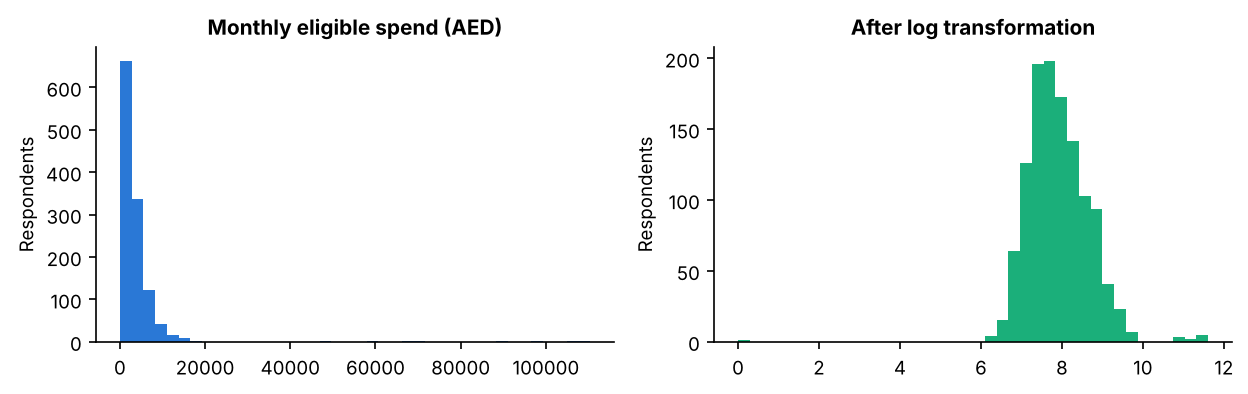

In [4]:
fig,ax=plt.subplots(1,2,figsize=(8.4,2.7)); ax[0].hist(c.B1_Monthly_Spend_Eligible_AED.dropna(),40,color=BLUE); ax[0].set(title='Monthly eligible spend (AED)',ylabel='Respondents'); ax[1].hist(c.Log_Spend.dropna(),40,color=AQUA); ax[1].set(title='After log transformation',ylabel='Respondents'); plt.tight_layout(); plt.savefig(F+'02_spend.png'); plt.show()

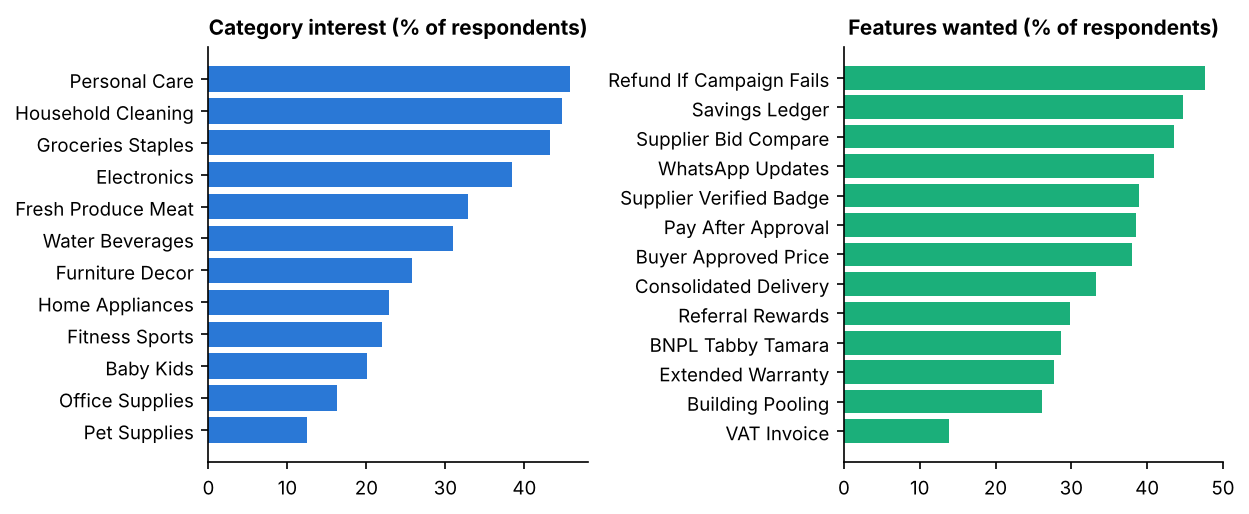

{'Electronics': 38.4, 'Groceries Staples': 43.2, 'Household Cleaning': 44.8, 'Personal Care': 45.8} {'Pet Supplies': 12.5, 'Office Supplies': 16.3} {'Supplier Bid Compare': 43.5, 'Savings Ledger': 44.8, 'Refund If Campaign Fails': 47.7} {'VAT Invoice': 13.9}


In [5]:
fig,ax=plt.subplots(1,2,figsize=(8.4,3.5))
a=(c.filter(like='CAT_').mean()*100).rename(lambda x:pretty(x[4:])).sort_values(); ax[0].barh(a.index,a.values,color=BLUE); ax[0].set_title('Category interest (% of respondents)')
b=(c.filter(like='FEAT_').mean()*100).rename(lambda x:pretty(x[5:])).sort_values(); ax[1].barh(b.index,b.values,color=AQUA); ax[1].set_title('Features wanted (% of respondents)')
plt.tight_layout(); plt.savefig(F+'03_demand.png'); plt.show(); print(a.round(1).tail(4).to_dict(),a.round(1).head(2).to_dict(),b.round(1).tail(3).to_dict(),b.round(1).head(1).to_dict())

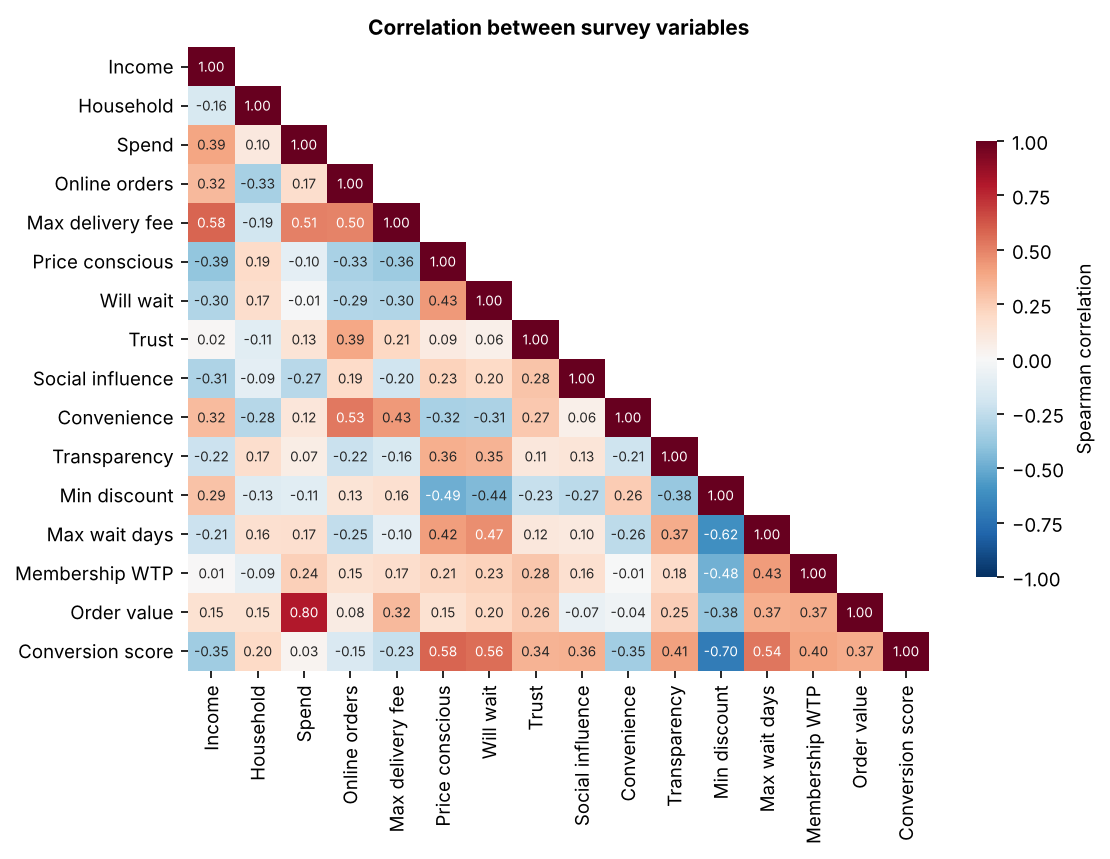

Min discount       -0.70
Income             -0.35
Convenience        -0.35
Max delivery fee   -0.23
Online orders      -0.15
Spend               0.03
Household           0.20
Trust               0.34
Social influence    0.36
Order value         0.37
Membership WTP      0.40
Transparency        0.41
Max wait days       0.54
Will wait           0.56
Price conscious     0.58
Spend            Order value         0.80
Min discount     Conversion score   -0.70
                 Max wait days      -0.62
Price conscious  Conversion score    0.58
Income           Max delivery fee    0.58
Will wait        Conversion score    0.56
Max wait days    Conversion score    0.54
Online orders    Convenience         0.53
Spend            Max delivery fee    0.51
Online orders    Max delivery fee    0.50


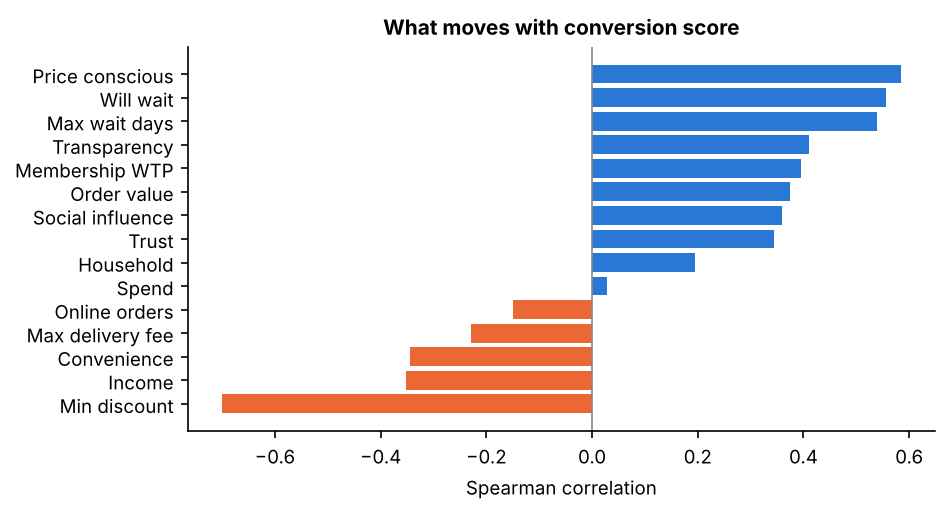

In [6]:
cols={'A7_Monthly_Income_AED':'Income','A6_Household_Size':'Household','B1_Monthly_Spend_Eligible_AED':'Spend','B2_Online_Orders_Per_Month':'Online orders','B6_Max_Delivery_Fee_AED':'Max delivery fee','C1_Price_Consciousness':'Price conscious','C2_Willing_To_Wait_For_Deal':'Will wait','C3_Trust_New_Platforms':'Trust','C4_Social_Influence':'Social influence','C5_Convenience_Priority':'Convenience','C7_Values_Price_Transparency':'Transparency','F1_Min_Discount_To_Switch_Pct':'Min discount','F2_Max_Wait_Days':'Max wait days','F3_Membership_WTP_AED_Month':'Membership WTP','G4_Expected_Order_Value_AED':'Order value','Conversion_Score_0to10':'Conversion score'}
R=c[list(cols)].rename(columns=cols).corr(method='spearman'); R.round(3).to_csv('../Results/EDA_Correlation_Matrix.csv')
fig,ax=plt.subplots(figsize=(7.6,5.8)); sns.heatmap(R,mask=np.triu(np.ones_like(R,bool),1),annot=True,fmt='.2f',annot_kws={'size':6.5},cmap='RdBu_r',vmin=-1,vmax=1,center=0,cbar_kws={'shrink':.7,'label':'Spearman correlation'},ax=ax); ax.set_title('Correlation between survey variables'); plt.tight_layout(); plt.savefig(F+'04_corr.png'); plt.show()
s=R['Conversion score'].drop('Conversion score').sort_values(); print(s.round(2).to_string())
pairs=R.where(np.triu(np.ones_like(R,bool),1)).stack().sort_values(key=abs,ascending=False); print(pairs.head(10).round(2).to_string())
fig,ax=plt.subplots(figsize=(6.4,3.5)); ax.barh(s.index,s.values,color=[ORANGE if v<0 else BLUE for v in s]); ax.axvline(0,color=GREY,lw=.8); ax.set(title='What moves with conversion score',xlabel='Spearman correlation'); plt.tight_layout(); plt.savefig(F+'05_corr_conv.png'); plt.show()

## Diagnostic views

Prior group buying {'No': 18.2, 'Yes, once or twice': 31.4, 'Yes, regularly': 48.5} {'No': 609, 'Yes, once or twice': 389, 'Yes, regularly': 202}
In WhatsApp buying group {'No': 19.2, 'Yes': 48.8} {'No': 860, 'Yes': 340}
Monthly income (AED) {'<10k': 46.9, '10-20k': 30.8, '20-35k': 30.8, '35k+': 13.4} {'<10k': 98, '10-20k': 506, '20-35k': 276, '35k+': 201}


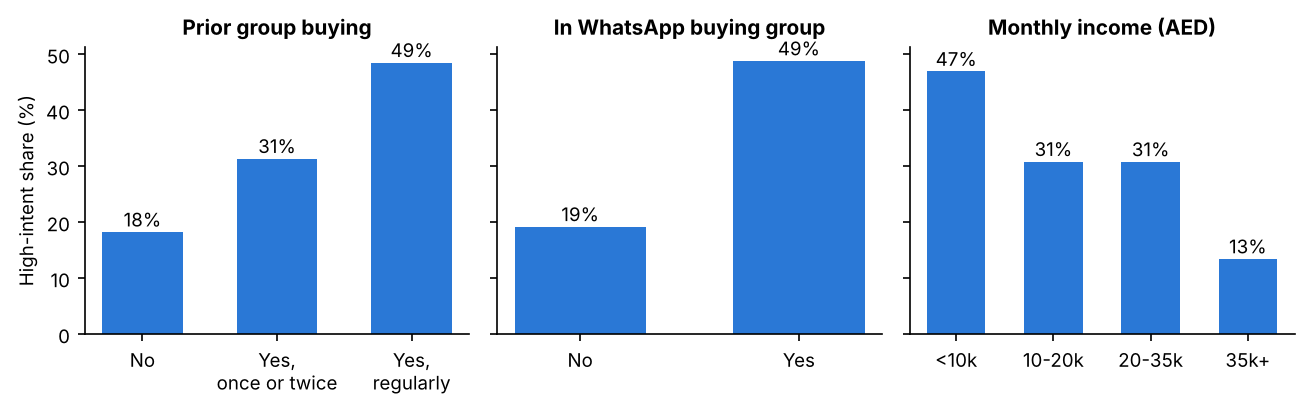

In [7]:
fig,ax=plt.subplots(1,3,figsize=(8.8,2.8),sharey=True)
for a_,col,ti,lab in [(ax[0],'B4_Used_Group_Buying_Before','Prior group buying',['No','Yes, once or twice','Yes, regularly']),(ax[1],'B5_In_Community_WhatsApp_Buying_Group','In WhatsApp buying group',['No','Yes']),(ax[2],'Income_Band','Monthly income (AED)',['<10k','10-20k','20-35k','35k+'])]:
    v=c.groupby(col,observed=True).High_Intent.mean().reindex(lab)*100; print(ti,v.round(1).to_dict(),c[col].value_counts().reindex(lab).to_dict()); a_.bar([x.replace(', ',',\n') for x in lab],v.values,color=BLUE,width=.6); a_.set_title(ti)
    for i,x in enumerate(v.values): a_.text(i,x+1,f'{x:.0f}%',ha='center')
ax[0].set_ylabel('High-intent share (%)'); plt.tight_layout(); plt.savefig(F+'06_intent_drivers.png'); plt.show()

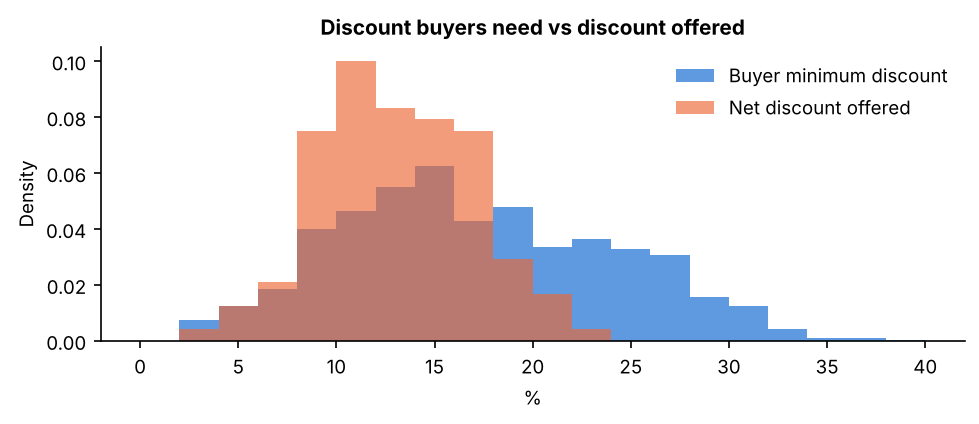

median F1 16.0 offer mean/med 13.1 12.965 share buyers min<=offer median 0.305


In [8]:
fig,ax=plt.subplots(figsize=(6.6,2.9)); ax.hist(c.F1_Min_Discount_To_Switch_Pct.dropna(),bins=range(0,41,2),color=BLUE,alpha=.75,density=True,label='Buyer minimum discount'); ax.hist(ca.Net_Discount_Pct,bins=range(0,41,2),color=ORANGE,alpha=.65,density=True,label='Net discount offered'); ax.set(title='Discount buyers need vs discount offered',xlabel='%',ylabel='Density'); ax.legend(frameon=False); plt.tight_layout(); plt.savefig(F+'07_discount_gap.png'); plt.show()
print('median F1',c.F1_Min_Discount_To_Switch_Pct.median(),'offer mean/med',ca.Net_Discount_Pct.mean().round(1),ca.Net_Discount_Pct.median(),'share buyers min<=offer median',(c.F1_Min_Discount_To_Switch_Pct<=ca.Net_Discount_Pct.median()).mean().round(3))

disc-paid pearson 0.811 n 97
         mean  size
Band               
<10%    0.422    13
10-13%  0.520    27
13-16%  0.605    27
16%+    0.745    30
slope 3.25


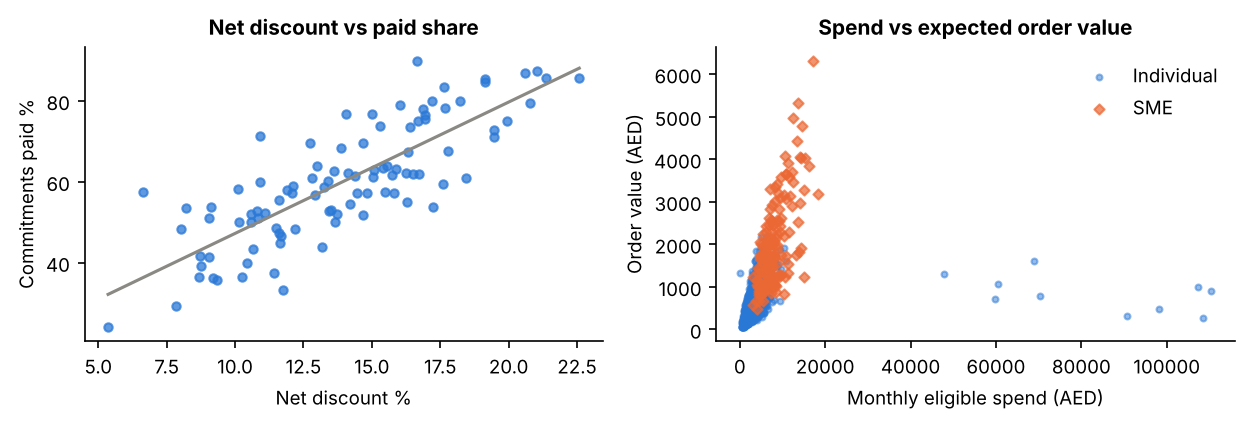

       B1_Monthly_Spend_Eligible_AED       G4_Expected_Order_Value_AED      
                              median  size                      median  size
Is_SME                                                                      
0                             2240.0  1042                       430.0  1042
1                             7505.0   158                      1750.0   158
sp ind/sme 0.73 0.6


In [9]:
k=ca[ca.Status=='Completed'].copy(); print('disc-paid pearson',k.Net_Discount_Pct.corr(k.Paid_Share).round(3),'n',len(k))
k['Band']=pd.cut(k.Net_Discount_Pct,[0,10,13,16,30],labels=['<10%','10-13%','13-16%','16%+']); print(k.groupby('Band',observed=True).Paid_Share.agg(['mean','size']).round(3).to_string())
fig,ax=plt.subplots(1,2,figsize=(8.4,2.9)); ax[0].scatter(k.Net_Discount_Pct,k.Paid_Share*100,s=16,color=BLUE,alpha=.75); m,b_=np.polyfit(k.Net_Discount_Pct,k.Paid_Share*100,1); xx=np.array([k.Net_Discount_Pct.min(),k.Net_Discount_Pct.max()]); ax[0].plot(xx,m*xx+b_,color=GREY); ax[0].set(title='Net discount vs paid share',xlabel='Net discount %',ylabel='Commitments paid %'); print('slope',round(m,2))
c2=pd.read_csv('../Dataset/customers_transformed.csv'); ax[1].scatter(c2[c2.Is_SME==0].B1_Monthly_Spend_Eligible_AED,c2[c2.Is_SME==0].G4_Expected_Order_Value_AED,s=8,color=BLUE,alpha=.5,label='Individual'); ax[1].scatter(c2[c2.Is_SME==1].B1_Monthly_Spend_Eligible_AED,c2[c2.Is_SME==1].G4_Expected_Order_Value_AED,s=12,marker='D',color=ORANGE,alpha=.7,label='SME'); ax[1].set(title='Spend vs expected order value',xlabel='Monthly eligible spend (AED)',ylabel='Order value (AED)'); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(F+'08_scatter.png'); plt.show()
print(c.groupby('Is_SME')[['B1_Monthly_Spend_Eligible_AED','G4_Expected_Order_Value_AED']].agg(['median','size']).to_string()); print('sp ind/sme',c[c.Is_SME==0][['B1_Monthly_Spend_Eligible_AED','G4_Expected_Order_Value_AED']].corr('spearman').iloc[0,1].round(2),c[c.Is_SME==1][['B1_Monthly_Spend_Eligible_AED','G4_Expected_Order_Value_AED']].corr('spearman').iloc[0,1].round(2))

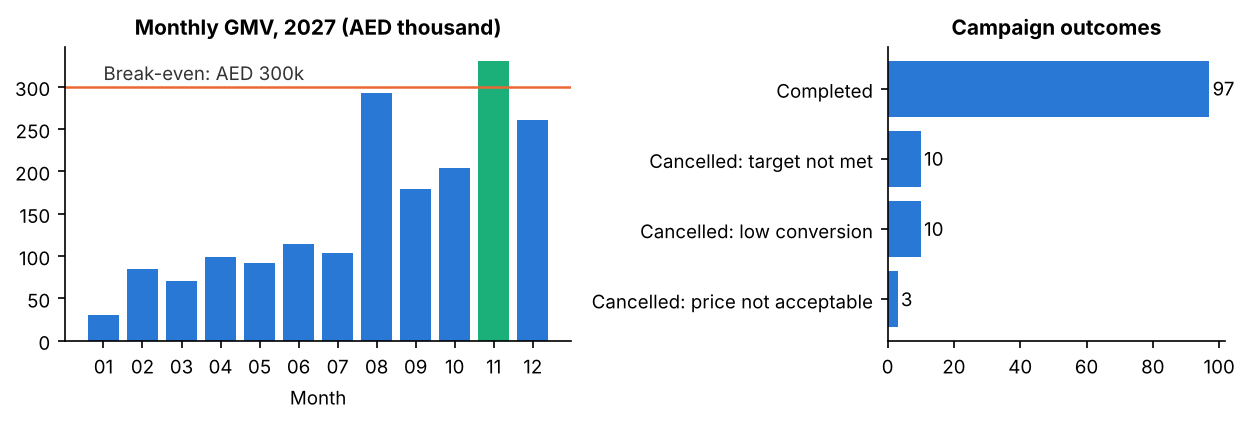

{'2027-01': 30669.0, '2027-02': 85021.0, '2027-03': 70999.0, '2027-04': 98446.0, '2027-05': 91926.0, '2027-06': 113942.0, '2027-07': 103395.0, '2027-08': 292685.0, '2027-09': 179512.0, '2027-10': 204098.0, '2027-11': 330320.0, '2027-12': 260865.0}
{'Cancelled - price not acceptable': 3, 'Cancelled - low conversion': 10, 'Cancelled - target not met': 10, 'Completed': 97}
                                  Target_Attainment  Net_Discount_Pct  Committed_Buyers
Status                                                                                 
Cancelled - low conversion                     0.88              9.54             40.60
Cancelled - price not acceptable               1.98              4.61             35.00
Cancelled - target not met                     0.61             10.71             31.50
Completed                                      1.61             13.93             37.35
                      GMV_AED  Committed_Value_AED  Paid
Category                                  

In [10]:
t['Month']=t.Campaign_Start.str[:7]; mm=t.groupby('Month').GMV_AED.sum()
fig,ax=plt.subplots(1,2,figsize=(8.4,2.9),gridspec_kw={'width_ratios':[3,2]}); ax[0].bar(mm.index.str[5:],mm.values/1000,color=[AQUA if v>=300000 else BLUE for v in mm.values]); ax[0].axhline(300,color=ORANGE,lw=1.2); ax[0].text(0,308,'Break-even: AED 300k',color='#333'); ax[0].set(title='Monthly GMV, 2027 (AED thousand)',xlabel='Month')
st=ca.Status.value_counts().sort_values(); ax[1].barh([x.replace('Cancelled - ','Cancelled: ') for x in st.index],st.values,color=BLUE); ax[1].set_title('Campaign outcomes'); [ax[1].text(v+1,i,v,va='center') for i,v in enumerate(st.values)]; plt.tight_layout(); plt.savefig(F+'09_gmv.png'); plt.show()
print(mm.round().to_dict()); print(st.to_dict()); print(ca.groupby('Status')[['Target_Attainment','Net_Discount_Pct','Committed_Buyers']].mean().round(2).to_string())
g=t.groupby('Category')[['GMV_AED','Committed_Value_AED','Paid']].agg({'GMV_AED':'sum','Committed_Value_AED':'sum','Paid':'mean'}).sort_values('GMV_AED',ascending=False); print(g.round(2).head(4).to_string())
tot=t.GMV_AED.sum();print(tot,t.Commission_AED.sum(),t.Variable_Cost_AED.sum(),t[t.Paid==1].Dispute.mean(),ca[ca.Status=='Completed'].On_Time.mean())